# Análisis del Dataset Maestro: Gasto Público, Impuestos, Crecimiento Económico e Inflación en México (2015–2025)

---

### Guía rápida de lectura del cuaderno
Este cuaderno presenta, paso a paso y en lenguaje claro, cómo se comportaron el gasto del gobierno, el cobro de impuestos, la economía y los precios en México entre **enero de 2015 y marzo de 2025**:

1. **Planteamiento y preguntas guía:** Qué queremos responder y con qué datos.
2. **Preparación del entorno y carga de datos:** Configuración de PySpark.
3. **Exploración inicial y diccionario de variables:** Qué contiene la capa Gold `data/gold/dataset_maestro` (123 meses, 43 columnas).
4. **Preparación de indicadores y rezagos temporales:** Por qué comparamos tasas de cambio anual (`%`) y el efecto de meses anteriores (1, 3, 6 y 12 meses atrás).
5. **Objetivo Específico 1 (Crecimiento económico - IGAE):** Qué tan conectados están el gasto y los impuestos (ISR e IVA) con la actividad económica y cuánto tarda en verse su efecto.
6. **Objetivo Específico 2 (Inflación - INPC):** Si cobrar más impuestos ayuda a frenar la subida de precios o si la impulsa al alza.
7. **Comparativo por periodos:** prepandemia, pandemia y pospandemia.
8. **Gráficas:** cinco visualizaciones explicadas para la presentación.
9. **Cómo trabajó Spark durante el análisis** (métricas de la Spark UI por sección).
10. **Conclusiones y limitaciones.**

> **Cómo leer los números.** Cada relación se acompaña de su **valor p**: la probabilidad de ver una relación así de fuerte solo por azar. Usamos el criterio habitual de **p < 0.05** para llamarla *estadísticamente significativa*. Con 105 meses, una correlación necesita ser mayor que ±0.19 para pasar ese umbral. Todas las relaciones son **asociaciones**, no prueban por sí solas que una variable cause la otra.

---

### Planteamiento del Problema
- **Pregunta de investigación:** ¿De qué manera influye la relación entre el dinero que gasta el gobierno (Secretaría de Hacienda) y lo que cobra en impuestos (SAT) en el crecimiento económico y en la subida de precios (inflación) en México, durante el periodo de enero de 2015 a marzo de 2025?
- **Objetivo General:** Evaluar cómo afectan de forma conjunta el gasto del gobierno y la recaudación de impuestos al crecimiento de la economía y al aumento del costo de vida en México mediante PySpark.
- **Objetivos Específicos:**
  1. **Crecimiento económico (IGAE):** Identificar qué tan conectados están el gasto público y los impuestos principales (ISR e IVA) con el crecimiento económico del país, y cuánto tiempo tarda en verse su impacto.
  2. **Estabilidad de precios (INPC):** Descubrir si aumentar el cobro de impuestos ayuda a frenar la subida de precios provocada por el gasto del gobierno o si, por el contrario, la presiona al alza.

## 1. Configuración del Entorno e Inicialización de PySpark

**¿Qué hacemos en este paso?**
- Creamos la sesión con `get_spark()` de `src/ingestion/loader.py`, la misma del pipeline: una instancia `local[*]` con 12 núcleos, `spark.sql.shuffle.partitions = 4` y *event log* activado. La justificación de esa configuración se muestra en `notebooks/01_ingesta.ipynb` y en `docs/guia_optimizacion.md`.
- Cada sección etiqueta sus jobs con `etapa()`; al final (Sección 8) se resume qué hizo Spark en cada parte del análisis, con datos de la Spark UI.
- El notebook lee la **capa Gold** (`data/gold/dataset_maestro`), generada por `notebooks/01_ingesta.ipynb` o por `python -m src.pipeline`.
- Cargamos las librerías de manipulación de datos (`pyspark.sql`), estadística y aprendizaje automático (`pyspark.ml`) y visualización (`matplotlib`, `seaborn`).
- Para las pruebas de significancia (valores p, causalidad de Granger, errores robustos) usamos `scipy` y `statsmodels` sobre la tabla mensual que ya resumió Spark: son 123 filas, así que no requieren cómputo distribuido.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from pyspark.sql import Window
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.ml.regression import LinearRegression

# Pruebas estadísticas sobre la serie mensual ya agregada en Spark (123 filas)
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

# Configuración estética uniforme para gráficas de presentación
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Ruta base del proyecto (funciona desde notebooks/ o desde la raíz del repo)
base_dir = Path('..').resolve() if Path('../src').exists() else Path('.').resolve()
sys.path.insert(0, str(base_dir))
from src.ingestion.loader import get_spark, GOLD_DIR
from src.monitoring import etapa, metricas

spark = get_spark('Integrador_02_Analisis')
spark.sparkContext.setLogLevel('ERROR')

print(f'Sesión de Spark activa: v{spark.version} | Spark UI: {spark.sparkContext.uiWebUrl}')
print(f'Directorio base detectado: {base_dir}')

Sesión de Spark activa: v3.5.9 | Spark UI: http://fedora:4040
Directorio base detectado: /home/mauriciodiaz/MCD/1/PGBD/INtegrador/Integrador-PGBD-26A


## 2. Carga y Exploración Inicial del Dataset Maestro

**¿Qué hacemos en este paso?**
1. **Lectura de la capa Gold:** cargamos `data/gold/dataset_maestro` (Parquet particionado por año), ordenado cronológicamente mes por mes.
2. **Revisión de cobertura:** Verificamos los **123 meses disponibles** (de enero de 2015 a marzo de 2025) y sus **43 variables**.

### Diccionario sencillo de las variables principales
| Variable | Fuente | ¿Qué mide en la vida real? |
| :--- | :--- | :--- |
| `fecha` / `anio` | Calendario | Mes de observación (`2015-01-01` a `2025-03-01`) |
| `shcp_xbc` | SHCP | Dinero total que gasta el gobierno federal cada mes (en millones de pesos) |
| `sat_total_tributarios` | SAT | Dinero total que cobra el SAT en impuestos cada mes (en millones de pesos) |
| `sat_isr` / `sat_iva` / `sat_ieps` | SAT | Cobro separado por Impuesto Sobre la Renta (ISR), IVA e IEPS |
| `igae_total` | INEGI | Termómetro mensual de la actividad económica del país (mide si la economía crece o se frena) |
| `inpc` | INEGI | Índice de precios de la canasta de bienes y servicios (sirve para calcular la inflación) |
| `ratio_tributario_gasto` | Calculada | Proporción del gasto del gobierno que se paga directamente con impuestos (`SAT / SHCP`) |

In [2]:
# Cargar la capa Gold generada por el pipeline medallion
etapa(spark, '2_carga')
ruta_maestro = str(GOLD_DIR / 'dataset_maestro')

print(f'Cargando dataset maestro desde: {ruta_maestro}')
# Sin orderBy: la ventana de la Sección 3 ya ordena por fecha (evita un shuffle extra)
df_maestro = spark.read.parquet(ruta_maestro)

print(f'Total de registros (meses): {df_maestro.count()}')
print(f'Total de variables: {len(df_maestro.columns)}')
df_maestro.printSchema()

Cargando dataset maestro desde: /home/mauriciodiaz/MCD/1/PGBD/INtegrador/Integrador-PGBD-26A/data/gold/dataset_maestro


Total de registros (meses): 123
Total de variables: 43
root
 |-- fecha: date (nullable = true)
 |-- shcp_xbc: double (nullable = true)
 |-- shcp_xbc10: double (nullable = true)
 |-- shcp_xbc11: double (nullable = true)
 |-- shcp_xbc1110: double (nullable = true)
 |-- shcp_xbc1111: double (nullable = true)
 |-- shcp_xbc1112: double (nullable = true)
 |-- shcp_xbc1113: double (nullable = true)
 |-- shcp_xbc1114: double (nullable = true)
 |-- shcp_xbc1120: double (nullable = true)
 |-- shcp_xbc1121: double (nullable = true)
 |-- shcp_xbc1122: double (nullable = true)
 |-- shcp_xbc1210: double (nullable = true)
 |-- shcp_xbc13: double (nullable = true)
 |-- shcp_xbc1310: double (nullable = true)
 |-- shcp_xbc1311: double (nullable = true)
 |-- shcp_xbc1312: double (nullable = true)
 |-- shcp_xbc1320: double (nullable = true)
 |-- shcp_xbc1321: double (nullable = true)
 |-- shcp_xbc1322: double (nullable = true)
 |-- shcp_xbc20: double (nullable = true)
 |-- shcp_xbc21: double (nullable = t

In [3]:
# Vista previa redondeada a 2 decimales para facilitar la lectura visual
cols_clave_vista = [
    'fecha', 'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
    'igae_total', 'inpc', 'ratio_tributario_gasto',
    'igae_var_anual_pct', 'inflacion_anual_pct'
]

print('=== MUESTRA DE LOS PRIMEROS 5 MESES (VARIABLES CLAVE REDONDEADAS) ===')
df_vista = df_maestro.select(
    'fecha',
    *[F.round(F.col(c), 2).alias(c) for c in cols_clave_vista if c != 'fecha']
)
df_vista.orderBy('fecha').show(5, truncate=False)

# Estadísticas descriptivas redondeadas a 2 decimales
cols_resumen = [
    'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
    'igae_total', 'inpc', 'ratio_tributario_gasto',
    'igae_var_anual_pct', 'inflacion_anual_pct', 'sat_real_var_anual_pct'
]

print('=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES ===')
df_stats = df_maestro.select(cols_resumen).summary('count', 'mean', 'stddev', 'min', '50%', 'max')
df_stats.select(
    'summary',
    *[F.round(F.col(c).cast('double'), 2).alias(c) for c in cols_resumen]
).show(truncate=False)

=== MUESTRA DE LOS PRIMEROS 5 MESES (VARIABLES CLAVE REDONDEADAS) ===


+----------+---------+---------------------+---------+--------+----------+-----+----------------------+------------------+-------------------+
|fecha     |shcp_xbc |sat_total_tributarios|sat_isr  |sat_iva |igae_total|inpc |ratio_tributario_gasto|igae_var_anual_pct|inflacion_anual_pct|
+----------+---------+---------------------+---------+--------+----------+-----+----------------------+------------------+-------------------+
|2015-01-01|340847.08|241470.74            |122658.44|75966.29|90.62     |87.11|0.71                  |NULL              |NULL               |
|2015-02-01|271271.83|173802.73            |82072.11 |57558.29|89.27     |87.28|0.64                  |NULL              |NULL               |
|2015-03-01|273661.92|250012.53            |173295.55|40290.72|94.33     |87.63|0.91                  |NULL              |NULL               |
|2015-04-01|274080.37|207142.09            |117225.9 |58155.94|92.93     |87.4 |0.76                  |NULL              |NULL               |

+-------+---------+---------------------+---------+---------+----------+------+----------------------+------------------+-------------------+----------------------+
|summary|shcp_xbc |sat_total_tributarios|sat_isr  |sat_iva  |igae_total|inpc  |ratio_tributario_gasto|igae_var_anual_pct|inflacion_anual_pct|sat_real_var_anual_pct|
+-------+---------+---------------------+---------+---------+----------+------+----------------------+------------------+-------------------+----------------------+
|count  |123.0    |123.0                |123.0    |123.0    |123.0     |123.0 |123.0                 |111.0             |111.0              |111.0                 |
|mean   |424581.57|291949.56            |159428.14|86817.57 |98.6      |109.3 |0.71                  |1.32              |4.93               |4.29                  |
|stddev |133963.17|81531.77             |54861.15 |24484.93 |5.15      |16.15 |0.13                  |5.81              |1.63               |10.06                 |
|min    |2

> **¿Qué significan estos datos?**
> - Contamos con **123 meses completos** (de enero de 2015 a marzo de 2025). Para calcular los cambios porcentuales respecto al año anterior quedan **111 meses**, ya que todo 2015 sirve como punto de partida.
> - Entre 2015 y 2025, el gobierno mexicano gastó en promedio **$424,582 millones de pesos al mes** y cobró **$291,950 millones en impuestos**.
> - Esto significa que, por cada 10 pesos que gastó el gobierno, **7 pesos salieron directamente de los impuestos** (`70.7%`) y el resto provino de otras fuentes (como ingresos petroleros, derechos o deuda).
> - En ese mismo periodo, la economía creció en promedio **1.32% al año** y los precios subieron **4.93% anual**.

## 3. Preparación de Indicadores Comparables y Rezagos Temporales en PySpark

**¿Por qué transformamos los datos antes de analizarlos?**
Si comparamos directamente montos en pesos a lo largo de 10 años, es fácil engañarnos: como los precios y el tamaño del país suben cada año, parece que todo crece junto aunque no exista una relación directa. Además, el dinero que el gobierno gasta o cobra hoy no cambia la economía de un día para otro; su efecto tarda varios meses en sentirse.

Por eso, usando funciones de ventana (`Window.orderBy('fecha')`) en PySpark creamos dos herramientas:
1. **Cambios porcentuales frente al mismo mes del año anterior (`_var_anual_pct`):** Permiten saber si el gasto, los impuestos, la economía o los precios subieron o bajaron respecto al año pasado, evitando confundirnos con meses que siempre tienen mucho movimiento (como diciembre).
2. **Valores de meses anteriores (`lag1`, `lag3`, `lag6`, `lag12`):** Nos permiten revisar si lo que el gobierno gastó o recaudó hace **1, 3, 6 o 12 meses** explica cómo se comportan la economía o los precios hoy.

In [4]:
etapa(spark, '3_indicadores')
w = Window.orderBy('fecha')

def variacion_anual(columna):
    """Calcula el cambio porcentual respecto al mismo mes del año anterior."""
    prev_12 = F.lag(columna, 12).over(w)
    return F.round(((F.col(columna) - prev_12) / prev_12) * 100, 2)

df_analitico = (
    df_maestro
    # 1. Tasas de variación anual (%)
    .withColumn('gasto_var_anual_pct', variacion_anual('shcp_xbc'))
    .withColumn('sat_var_anual_pct', variacion_anual('sat_total_tributarios'))
    # 2. Rezagos en niveles (1, 3, 6 y 12 meses)
    .withColumn('gasto_lag1', F.lag('shcp_xbc', 1).over(w))
    .withColumn('gasto_lag3', F.lag('shcp_xbc', 3).over(w))
    .withColumn('gasto_lag6', F.lag('shcp_xbc', 6).over(w))
    .withColumn('shcp_lag12', F.lag('shcp_xbc', 12).over(w))
    .withColumn('sat_lag1', F.lag('sat_total_tributarios', 1).over(w))
    .withColumn('sat_lag3', F.lag('sat_total_tributarios', 3).over(w))
    .withColumn('sat_lag6', F.lag('sat_total_tributarios', 6).over(w))
    .withColumn('sat_lag12', F.lag('sat_total_tributarios', 12).over(w))
    .withColumn('ratio_lag3', F.lag('ratio_tributario_gasto', 3).over(w))
    .withColumn('ratio_lag6', F.lag('ratio_tributario_gasto', 6).over(w))
)

# Guardamos en memoria caché para acelerar los siguientes cálculos
df_analitico.cache()
print('Variables analíticas y rezagos creados exitosamente.')

df_analitico.select(
    'fecha',
    F.round('igae_total', 2).alias('igae_total'),
    'igae_var_anual_pct',
    'inflacion_anual_pct',
    'gasto_var_anual_pct',
    'sat_var_anual_pct',
    F.round('ratio_tributario_gasto', 2).alias('ratio_tributario_gasto')
).dropna().show(5, truncate=False)

Variables analíticas y rezagos creados exitosamente.


+----------+----------+------------------+-------------------+-------------------+-----------------+----------------------+
|fecha     |igae_total|igae_var_anual_pct|inflacion_anual_pct|gasto_var_anual_pct|sat_var_anual_pct|ratio_tributario_gasto|
+----------+----------+------------------+-------------------+-------------------+-----------------+----------------------+
|2016-01-01|91.74     |1.23              |2.61               |3.11               |1.32             |0.7                   |
|2016-02-01|92.73     |3.87              |2.87               |-4.59              |12.55            |0.76                  |
|2016-03-01|94.13     |-0.22             |2.6                |-3.56              |13.15            |1.07                  |
|2016-04-01|95.75     |3.03              |2.54               |21.52              |14.74            |0.71                  |
|2016-05-01|96.0      |2.11              |2.6                |29.73              |22.11            |0.58                  |
+-------

### Cómo ejecuta Spark esta preparación

`df_analitico` se reutiliza en todas las secciones siguientes, así que se guarda en caché (`cache()`). El plan físico muestra cómo se construye la primera vez:

In [5]:
df_analitico.explain('formatted')

== Physical Plan ==
AdaptiveSparkPlan (15)
+- InMemoryTableScan (1)
      +- InMemoryRelation (2)
            +- AdaptiveSparkPlan (14)
               +- == Final Plan ==
                  * Project (9)
                  +- Window (8)
                     +- * Sort (7)
                        +- ShuffleQueryStage (6), Statistics(sizeInBytes=42.3 KiB, rowCount=123)
                           +- Exchange (5)
                              +- * ColumnarToRow (4)
                                 +- Scan parquet  (3)
               +- == Initial Plan ==
                  Project (13)
                  +- Window (12)
                     +- Sort (11)
                        +- Exchange (10)
                           +- Scan parquet  (3)


(1) InMemoryTableScan
Output [55]: [fecha#0, shcp_xbc#1, shcp_xbc10#2, shcp_xbc11#3, shcp_xbc1110#4, shcp_xbc1111#5, shcp_xbc1112#6, shcp_xbc1113#7, shcp_xbc1114#8, shcp_xbc1120#9, shcp_xbc1121#10, shcp_xbc1122#11, shcp_xbc1210#12, shcp_xbc13#13, shcp_xbc13

> **Cómo leer el plan (de abajo hacia arriba):**
> 1. **`Scan parquet`** lee la capa Gold: 43 columnas repartidas en una carpeta por año (`anio=2015` … `anio=2025`). `ColumnarToRow` convierte el formato columnar de Parquet en filas para los operadores siguientes.
> 2. **`Exchange` (SinglePartition) → `Sort` → `Window`**: los `lag(12)` y rezagos usan `Window.orderBy('fecha')` sin `partitionBy`, así que Spark reúne las **123 filas en una sola partición**, las ordena y recorre la serie. Es necesario: cada mes necesita el mismo mes del año anterior.
> 3. **`AdaptiveSparkPlan`** con *Initial* y *Final Plan*: AQE ajusta el plan con las estadísticas reales del shuffle (`Statistics(sizeInBytes=42.3 KiB, rowCount=123)`).
> 4. **`InMemoryRelation` / `InMemoryTableScan`**: tras la primera acción, `df_analitico` queda en memoria, y las ~60 consultas de las secciones 4 a 7 lo leen de ahí en lugar de recalcular la ventana desde Parquet.
>
> **Optimización aplicada:** originalmente la carga hacía `spark.read.parquet(...).orderBy('fecha')`. Eso agregaba un **segundo `Exchange`** (un *range partitioning* para ordenar), redundante porque la ventana vuelve a ordenar. Al quitarlo, el análisis completo pasó de **123 a 77 jobs** y de **603 a 327 tareas**, con los mismos resultados (Sección 8).

## 4. Objetivo Específico 1: Conexión y Tiempo de Efecto en el Crecimiento Económico (IGAE)

**Pregunta guía:** *¿Qué tan conectados están el gasto público y los impuestos principales (ISR e IVA) con la actividad económica, y cuánto tiempo tarda en verse su impacto?*

Para responder con claridad y evitar falsas alarmas estadísticas, revisamos los datos en **dos pasos**:
- **Paso 4A (Comparación en montos en pesos):** Medimos qué tanto avanzan juntos los montos recaudados y gastados frente al nivel de actividad económica (`igae_total`).
- **Paso 4B (Comparación en porcentajes de crecimiento anual y meses anteriores):** Comparamos el ritmo de crecimiento (`%`) en el mismo mes y con **1, 3 y 6 meses de diferencia** (`lag1`, `lag3`, `lag6`) para ver qué ocurre primero y cuánto tarda en notarse.

In [6]:
etapa(spark, '4_objetivo1')
# Paso 4A: Correlación en niveles nominales (contemporánea y con rezagos)
cols_impuestos = [c for c in df_maestro.columns if any(k in c.lower() for k in ['isr', 'iva', 'sat_total'])]
print('Columnas tributarias disponibles:', cols_impuestos)

vars_obj1 = ['igae_total', 'shcp_xbc', 'gasto_lag1', 'gasto_lag3', 'gasto_lag6', 'shcp_lag12'] + \
            cols_impuestos + ['sat_lag1', 'sat_lag3', 'sat_lag6', 'sat_lag12']

vars_obj1 = list(dict.fromkeys([c for c in vars_obj1 if c in df_analitico.columns]))

df_corr1 = df_analitico.select(vars_obj1).dropna()
assembler1 = VectorAssembler(inputCols=vars_obj1, outputCol='features')
vec_df1 = assembler1.transform(df_corr1).select('features')

corr_matrix1 = Correlation.corr(vec_df1, 'features', 'pearson').head()[0].toArray()
df_corr_igae = pd.DataFrame(corr_matrix1, index=vars_obj1, columns=vars_obj1)

print('\n=== PASO 4A: CORRELACIÓN EN NIVELES CON EL IGAE TOTAL ===')
res_igae = df_corr_igae[['igae_total']].sort_values(by='igae_total', ascending=False)
print(res_igae.round(4))

Columnas tributarias disponibles: ['sat_total_tributarios', 'sat_isr', 'sat_iva', 'sat_total_real', 'ratio_isr_tributario']



=== PASO 4A: CORRELACIÓN EN NIVELES CON EL IGAE TOTAL ===
                       igae_total
igae_total                 1.0000
sat_iva                    0.4808
sat_total_tributarios      0.4652
gasto_lag6                 0.4577
shcp_xbc                   0.4518
sat_lag6                   0.4230
sat_lag3                   0.4035
shcp_lag12                 0.4034
gasto_lag3                 0.3966
sat_isr                    0.3837
sat_lag12                  0.3501
sat_lag1                   0.3163
sat_total_real             0.2958
gasto_lag1                 0.2638
ratio_isr_tributario       0.0192


In [7]:
etapa(spark, '4_objetivo1')
# Paso 4B: Relación en porcentajes de crecimiento anual (reutilizando la ventana w)
df_tasas = (
    df_analitico
    .select(
        'fecha', 'igae_var_anual_pct', 'gasto_var_anual_pct',
        'sat_var_anual_pct', 'inflacion_anual_pct', 'ratio_tributario_gasto'
    )
    .withColumn('gasto_var_lag1', F.lag('gasto_var_anual_pct', 1).over(w))
    .withColumn('gasto_var_lag3', F.lag('gasto_var_anual_pct', 3).over(w))
    .withColumn('gasto_var_lag6', F.lag('gasto_var_anual_pct', 6).over(w))
    .withColumn('sat_var_lag1', F.lag('sat_var_anual_pct', 1).over(w))
    .withColumn('sat_var_lag3', F.lag('sat_var_anual_pct', 3).over(w))
    .withColumn('sat_var_lag6', F.lag('sat_var_anual_pct', 6).over(w))
    .dropna()
)

# Rezago de 12 meses en tasas: se guarda aparte porque exige 6 meses más de historia (N = 99)
df_tasas12 = (
    df_analitico
    .select('fecha', 'igae_var_anual_pct', 'inflacion_anual_pct', 'gasto_var_anual_pct', 'sat_var_anual_pct', 'ratio_tributario_gasto')
    .withColumn('gasto_var_lag12', F.lag('gasto_var_anual_pct', 12).over(w))
    .withColumn('sat_var_lag12', F.lag('sat_var_anual_pct', 12).over(w))
    .dropna()
)

print(f'Observaciones válidas tras aplicar tasas anuales y rezagos de hasta 6 meses: {df_tasas.count()} meses')

cols_tasas = [c for c in df_tasas.columns if c != 'fecha']
vec_tasas = VectorAssembler(inputCols=cols_tasas, outputCol='features').transform(df_tasas)
mat_tasas = Correlation.corr(vec_tasas, 'features', 'pearson').head()[0].toArray()
pdf_corr_tasas = pd.DataFrame(mat_tasas, index=cols_tasas, columns=cols_tasas)

print('\n=== PASO 4B: RELACIÓN EN PORCENTAJES DE CRECIMIENTO ANUAL (CORTO Y MEDIANO PLAZO) ===')
print(pdf_corr_tasas[['igae_var_anual_pct', 'inflacion_anual_pct']].round(3))

Observaciones válidas tras aplicar tasas anuales y rezagos de hasta 6 meses: 105 meses



=== PASO 4B: RELACIÓN EN PORCENTAJES DE CRECIMIENTO ANUAL (CORTO Y MEDIANO PLAZO) ===
                        igae_var_anual_pct  inflacion_anual_pct
igae_var_anual_pct                   1.000                0.437
gasto_var_anual_pct                  0.148                0.054
sat_var_anual_pct                    0.327               -0.045
inflacion_anual_pct                  0.437                1.000
ratio_tributario_gasto               0.006               -0.073
gasto_var_lag1                       0.029                0.079
gasto_var_lag3                       0.106                0.048
gasto_var_lag6                       0.095                0.151
sat_var_lag1                         0.158               -0.075
sat_var_lag3                        -0.006               -0.085
sat_var_lag6                         0.172                0.052


### Paso 4C: ¿Qué relaciones son estadísticamente significativas?

Spark calcula cada correlación con `F.corr`; con ella y el número de meses obtenemos el valor p (prueba t de Pearson). Incluimos el rezago de **12 meses**, que exige un año más de historia (N = 99).

In [8]:
etapa(spark, '4_objetivo1')
def valor_p(r, n):
    # Prueba t para una correlación de Pearson con n observaciones
    t = r * np.sqrt((n - 2) / (1 - r**2))
    return 2 * stats.t.sf(abs(t), n - 2)

def tabla_significancia(df, objetivo, explicativas):
    n = df.count()
    fila = df.agg(*[F.corr(c, objetivo).alias(c) for c in explicativas]).first().asDict()
    return pd.DataFrame(
        [(c, round(r, 3), round(valor_p(r, n), 4), n) for c, r in fila.items()],
        columns=['variable', 'r', 'valor_p', 'N'],
    ).assign(significativa=lambda d: np.where(d.valor_p < 0.05, 'Sí', 'No'))

explicativas = ['gasto_var_anual_pct', 'gasto_var_lag1', 'gasto_var_lag3', 'gasto_var_lag6',
                'sat_var_anual_pct', 'sat_var_lag1', 'sat_var_lag3', 'sat_var_lag6', 'ratio_tributario_gasto']
sig_igae = pd.concat([
    tabla_significancia(df_tasas, 'igae_var_anual_pct', explicativas),
    tabla_significancia(df_tasas12, 'igae_var_anual_pct', ['gasto_var_lag12', 'sat_var_lag12']),
])
sig_inf = pd.concat([
    tabla_significancia(df_tasas, 'inflacion_anual_pct', explicativas),
    tabla_significancia(df_tasas12, 'inflacion_anual_pct', ['gasto_var_lag12', 'sat_var_lag12']),
])
print('=== CORRELACIÓN CON EL CRECIMIENTO ECONÓMICO (IGAE, var. anual %) ===')
print(sig_igae.to_string(index=False))
print('\n=== CORRELACIÓN CON LA INFLACIÓN ANUAL (INPC) ===')
print(sig_inf.to_string(index=False))

=== CORRELACIÓN CON EL CRECIMIENTO ECONÓMICO (IGAE, var. anual %) ===
              variable      r  valor_p   N significativa
   gasto_var_anual_pct  0.148   0.1307 105            No
        gasto_var_lag1  0.029   0.7663 105            No
        gasto_var_lag3  0.106   0.2828 105            No
        gasto_var_lag6  0.095   0.3365 105            No
     sat_var_anual_pct  0.327   0.0007 105            Sí
          sat_var_lag1  0.158   0.1064 105            No
          sat_var_lag3 -0.006   0.9488 105            No
          sat_var_lag6  0.172   0.0800 105            No
ratio_tributario_gasto  0.006   0.9513 105            No
       gasto_var_lag12  0.026   0.7969  99            No
         sat_var_lag12 -0.147   0.1477  99            No

=== CORRELACIÓN CON LA INFLACIÓN ANUAL (INPC) ===
              variable      r  valor_p   N significativa
   gasto_var_anual_pct  0.054   0.5831 105            No
        gasto_var_lag1  0.079   0.4202 105            No
        gasto_var_lag3  

### Paso 4D: ¿Quién se mueve primero? Prueba de causalidad de Granger

Una correlación no dice qué variable va primero. La **prueba de Granger** pregunta: *¿los valores pasados de X ayudan a predecir Y, más allá de lo que ya predicen los valores pasados de Y?* Si el valor p es menor que 0.05, decimos que **X anticipa a Y** (en sentido de Granger; sigue sin ser una prueba de causalidad económica).

La prueba exige series *estacionarias* (sin tendencia persistente). Primero lo revisamos con la prueba de Dickey-Fuller aumentada (ADF): un valor p < 0.05 indica serie estacionaria.

In [9]:
etapa(spark, '4_objetivo1')
pdf_series = df_analitico.select('fecha', 'igae_var_anual_pct', 'inflacion_anual_pct',
                                 'gasto_var_anual_pct', 'sat_var_anual_pct', 'ratio_tributario_gasto') \
                         .orderBy('fecha').toPandas().dropna()

adf = pd.DataFrame(
    [(c, round(adfuller(pdf_series[c], autolag='AIC')[1], 4)) for c in pdf_series.columns if c != 'fecha'],
    columns=['serie', 'valor_p_ADF'],
).assign(estacionaria=lambda d: np.where(d.valor_p_ADF < 0.05, 'Sí', 'No (cautela)'))
print('=== ESTACIONARIEDAD (ADF) ===')
print(adf.to_string(index=False))

pares = [
    ('gasto_var_anual_pct', 'igae_var_anual_pct'),
    ('sat_var_anual_pct', 'igae_var_anual_pct'),
    ('igae_var_anual_pct', 'sat_var_anual_pct'),
    ('gasto_var_anual_pct', 'inflacion_anual_pct'),
    ('sat_var_anual_pct', 'inflacion_anual_pct'),
    ('ratio_tributario_gasto', 'inflacion_anual_pct'),
]
filas = []
for x, y in pares:
    res = grangercausalitytests(pdf_series[[y, x]], maxlag=6)
    ps = {f'rezago_{k}': round(res[k][0]['ssr_ftest'][1], 3) for k in res}
    filas.append({'¿X anticipa a Y?': f'{x} -> {y}', **ps,
                  'significativa (algún rezago)': 'Sí' if min(ps.values()) < 0.05 else 'No'})
granger = pd.DataFrame(filas)
print('\n=== CAUSALIDAD DE GRANGER (valores p por rezago, en meses) ===')
print(granger.to_string(index=False))

=== ESTACIONARIEDAD (ADF) ===
                 serie  valor_p_ADF estacionaria
    igae_var_anual_pct       0.0002           Sí
   inflacion_anual_pct       0.3719 No (cautela)
   gasto_var_anual_pct       0.1686 No (cautela)
     sat_var_anual_pct       0.0001           Sí
ratio_tributario_gasto       0.2751 No (cautela)



Granger Causality
number of lags (no zero) 1
ssr based F test:         F=1.5943  , p=0.2095  , df_denom=107, df_num=1
ssr based chi2 test:   chi2=1.6390  , p=0.2005  , df=1
likelihood ratio test: chi2=1.6269  , p=0.2021  , df=1
parameter F test:         F=1.5943  , p=0.2095  , df_denom=107, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=1.2086  , p=0.3028  , df_denom=104, df_num=2
ssr based chi2 test:   chi2=2.5334  , p=0.2818  , df=2
likelihood ratio test: chi2=2.5044  , p=0.2859  , df=2
parameter F test:         F=1.2086  , p=0.3028  , df_denom=104, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=0.9056  , p=0.4412  , df_denom=101, df_num=3
ssr based chi2 test:   chi2=2.9051  , p=0.4065  , df=3
likelihood ratio test: chi2=2.8667  , p=0.4126  , df=3
parameter F test:         F=0.9056  , p=0.4412  , df_denom=101, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=0.7119  , p=0.5857  

### Paso 4E: Robustez: gasto total (XBC) frente a gasto programable (XBC10)

El indicador principal usa `shcp_xbc`, el **gasto total** del Gobierno Federal, que incluye gasto no programable (costo financiero de la deuda y participaciones a estados). La pregunta de investigación habla de **gasto programable** (`shcp_xbc10`, ~71 % del total). Repetimos las pruebas clave con ambos para comprobar que las conclusiones no dependen de esa elección.

In [10]:
etapa(spark, '4_objetivo1')
df_prog = (
    df_maestro.select('fecha', 'shcp_xbc', 'shcp_xbc10', 'igae_var_anual_pct', 'inflacion_anual_pct')
    .withColumn('gasto_total_var', variacion_anual('shcp_xbc'))
    .withColumn('gasto_programable_var', variacion_anual('shcp_xbc10'))
)
filas = []
for serie in ['gasto_total_var', 'gasto_programable_var']:
    for k in [0, 1, 3, 6, 12]:
        sub = df_prog.withColumn('x', F.lag(serie, k).over(w) if k else F.col(serie)).dropna(subset=['x', 'igae_var_anual_pct'])
        n = sub.count()
        r_igae, r_inf = sub.agg(F.corr('x', 'igae_var_anual_pct'), F.corr('x', 'inflacion_anual_pct')).first()
        filas.append({'gasto': serie, 'rezago': k, 'N': n,
                      'r IGAE': round(r_igae, 3), 'p IGAE': round(valor_p(r_igae, n), 3),
                      'r inflación': round(r_inf, 3), 'p inflación': round(valor_p(r_inf, n), 3)})
print(pd.DataFrame(filas).to_string(index=False))

pdf_prog = df_prog.select('inflacion_anual_pct', 'igae_var_anual_pct', 'gasto_total_var', 'gasto_programable_var').toPandas().dropna()
for serie in ['gasto_total_var', 'gasto_programable_var']:
    for y in ['igae_var_anual_pct', 'inflacion_anual_pct']:
        res = grangercausalitytests(pdf_prog[[y, serie]], maxlag=6)
        print(f'Granger {serie} -> {y}:', [float(round(res[k][0]['ssr_ftest'][1], 3)) for k in res])

                gasto  rezago   N  r IGAE  p IGAE  r inflación  p inflación
      gasto_total_var       0 111   0.147   0.124        0.056        0.558
      gasto_total_var       1 110   0.030   0.759        0.070        0.469
      gasto_total_var       3 108   0.102   0.294        0.077        0.430
      gasto_total_var       6 105   0.095   0.337        0.151        0.125
      gasto_total_var      12  99   0.026   0.797        0.062        0.540
gasto_programable_var       0 111   0.098   0.307       -0.011        0.910
gasto_programable_var       1 110  -0.000   0.997        0.007        0.943
gasto_programable_var       3 108   0.102   0.295        0.038        0.700
gasto_programable_var       6 105   0.020   0.838        0.110        0.263
gasto_programable_var      12  99   0.057   0.578        0.095        0.352

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=1.5943  , p=0.2095  , df_denom=107, df_num=1
ssr based chi2 test:   chi2=1.6390  , p=0.200

ssr based F test:         F=0.9056  , p=0.4412  , df_denom=101, df_num=3
ssr based chi2 test:   chi2=2.9051  , p=0.4065  , df=3
likelihood ratio test: chi2=2.8667  , p=0.4126  , df=3
parameter F test:         F=0.9056  , p=0.4412  , df_denom=101, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=0.7119  , p=0.5857  , df_denom=98, df_num=4
ssr based chi2 test:   chi2=3.1091  , p=0.5397  , df=4
likelihood ratio test: chi2=3.0648  , p=0.5470  , df=4
parameter F test:         F=0.7119  , p=0.5857  , df_denom=98, df_num=4

Granger Causality
number of lags (no zero) 5
ssr based F test:         F=0.9486  , p=0.4535  , df_denom=95, df_num=5
ssr based chi2 test:   chi2=5.2921  , p=0.3813  , df=5
likelihood ratio test: chi2=5.1643  , p=0.3962  , df=5
parameter F test:         F=0.9486  , p=0.4535  , df_denom=95, df_num=5

Granger Causality
number of lags (no zero) 6
ssr based F test:         F=0.7662  , p=0.5984  , df_denom=92, df_num=6
ssr based chi2 test:   chi

> **Resultado:** con gasto programable las conclusiones no cambian. Ninguna correlación con el IGAE es significativa, y el gasto vuelve a **anticipar la inflación a 5–6 meses** en Granger (p ≈ 0.03–0.04, frente a ≈ 0.01 con gasto total). El resto del análisis conserva el gasto total.

> **¿Qué nos dicen estos números sobre el crecimiento económico?**
> 1. **En montos en pesos (Paso 4A):** el IVA, la recaudación total y el gasto aparecen correlacionados con el IGAE (entre `0.40` y `0.48`). Esta lectura es engañosa por sí sola: todas son series que crecen con el tiempo (precios y tamaño de la economía), así que se mueven juntas aunque no exista relación directa. Por eso la lectura válida es la de tasas de crecimiento.
> 2. **En ritmo de crecimiento anual (Pasos 4B y 4C):**
>    - **La recaudación va de la mano con la economía:** su crecimiento se asocia con el del IGAE en el mismo mes (`r ≈ 0.33`, valor p < 0.01, significativa).
>    - **El gasto público no muestra una relación significativa con el crecimiento** en ningún horizonte probado (mismo mes, 1, 3, 6 ni 12 meses; todas con valor p > 0.1). Las correlaciones de `0.09` a `0.15` son demasiado débiles para distinguirlas del azar con 105 meses.
> 3. **¿Quién va primero? (Paso 4D, Granger):** el crecimiento del IGAE **anticipa** el de la recaudación (valor p < 0.05 en los rezagos de 1 a 6 meses), pero la recaudación **no** anticipa al IGAE. Es decir: **la economía mueve a los impuestos, y no al revés.** Cuando a empresas y familias les va bien, el SAT recauda más.
>
> **Respuesta al Objetivo 1:** los impuestos (ISR e IVA) están conectados con la actividad económica de forma inmediata, pero como *consecuencia* del crecimiento. Con datos mensuales de 2015 a 2025 **no encontramos evidencia** de que el gasto público impulse el IGAE en un plazo de 0 a 12 meses.

## 5. Objetivo Específico 2: Efecto Conjunto del Gasto e Impuestos sobre la Inflación (INPC)

**Pregunta guía:** *¿Aumentar el cobro de impuestos ayuda a frenar la subida de precios provocada por el gasto del gobierno o la presiona al alza?*

Para responder de manera clara y comprobable, analizamos el problema desde dos ángulos:
- **Paso 5A (Modelo estadístico en PySpark ML):** Estimamos cómo se mueve la inflación anual cuando cambian al mismo tiempo el gasto del gobierno (actual y de hace 3 meses), el cobro de impuestos (actual y de hace 3 meses), la proporción del gasto cubierta con impuestos (`ratio_tributario_gasto`) y el ritmo de la economía (`igae_var_anual_pct`).
- **Paso 5B (Comparación práctica por escenarios):** Dividimos los 105 meses analizados en dos grupos reales: los meses donde el cobro de impuestos creció más rápido que el gasto vs. los meses donde el gasto creció igual o más rápido que los impuestos.

In [11]:
etapa(spark, '5_objetivo2')
# Paso 5A: Modelo de Regresión Lineal Multivariada en PySpark ML
features_inflacion = [
    'gasto_var_anual_pct', 'gasto_var_lag3',
    'sat_var_anual_pct', 'sat_var_lag3',
    'ratio_tributario_gasto', 'igae_var_anual_pct'
]

df_ml_inf = (
    df_tasas
    .select(['inflacion_anual_pct'] + features_inflacion)
    .dropna()
)

assembler_inf = VectorAssembler(inputCols=features_inflacion, outputCol='features')
data_inf = assembler_inf.transform(df_ml_inf).select('features', F.col('inflacion_anual_pct').alias('label'))

# regParam=0 y solver 'normal' (mínimos cuadrados ordinarios): así Spark reporta errores estándar y valores p
lr = LinearRegression(featuresCol='features', labelCol='label', regParam=0.0, solver='normal')
modelo_inf = lr.fit(data_inf)

print('=== PASO 5A: MODELO ECONOMÉTRICO EN PYSPARK (OBJETIVO: INFLACIÓN ANUAL %) ===')
print(f'R² (Varianza explicada): {modelo_inf.summary.r2:.4f} ({modelo_inf.summary.r2*100:.1f}%)')
print(f'RMSE (Error cuadrático medio): {modelo_inf.summary.rootMeanSquaredError:.4f} puntos porcentuales')
print(f'Intercepto: {modelo_inf.intercept:.4f}\n')

resumen = modelo_inf.summary
coef_df = pd.DataFrame({
    'variable': features_inflacion + ['intercepto'],
    'coeficiente': list(modelo_inf.coefficients.toArray()) + [modelo_inf.intercept],
    'error_estandar': resumen.coefficientStandardErrors,
    'valor_p (Spark, OLS)': resumen.pValues,
}).round(4)
print(coef_df.to_string(index=False))

=== PASO 5A: MODELO ECONOMÉTRICO EN PYSPARK (OBJETIVO: INFLACIÓN ANUAL %) ===
R² (Varianza explicada): 0.2355 (23.5%)
RMSE (Error cuadrático medio): 1.3706 puntos porcentuales
Intercepto: 5.5315

              variable  coeficiente  error_estandar  valor_p (Spark, OLS)
   gasto_var_anual_pct      -0.0017          0.0101                0.8636
        gasto_var_lag3       0.0044          0.0097                0.6472
     sat_var_anual_pct      -0.0303          0.0152                0.0489
          sat_var_lag3      -0.0080          0.0141                0.5724
ratio_tributario_gasto      -0.4485          1.2017                0.7098
    igae_var_anual_pct       0.1319          0.0249                0.0000
            intercepto       5.5315          0.8880                0.0000


### Paso 5A.1: Robustez: errores estándar corregidos por autocorrelación

Los valores p de Spark suponen que los errores de meses distintos son independientes. En series mensuales de tasas anuales eso no se cumple: el estadístico **Durbin-Watson** (cercano a 2 si no hay autocorrelación, cercano a 0 si es fuerte) lo mide. Si hay autocorrelación, los valores p de mínimos cuadrados ordinarios salen **demasiado optimistas**, así que reestimamos con errores **HAC de Newey-West** (12 rezagos). Además añadimos una variable por periodo (pandemia y pospandemia) para separar los choques de esos años.

In [12]:
etapa(spark, '5_objetivo2')
pdf_ml = df_ml_inf.toPandas()
X = sm.add_constant(pdf_ml[features_inflacion])
y = pdf_ml['inflacion_anual_pct']
ols = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(f'Durbin-Watson: {sm.stats.durbin_watson(ols.resid):.3f}  (2 = sin autocorrelación)')

# Mismo modelo + efectos de periodo
pdf_per = df_tasas.select('fecha', 'inflacion_anual_pct', *features_inflacion).toPandas()
pdf_per['pandemia'] = ((pdf_per.fecha >= pd.Timestamp('2020-03-01').date()) & (pdf_per.fecha < pd.Timestamp('2022-01-01').date())).astype(float)
pdf_per['pospandemia'] = (pdf_per.fecha >= pd.Timestamp('2022-01-01').date()).astype(float)
Xp = sm.add_constant(pdf_per[features_inflacion + ['pandemia', 'pospandemia']])
hac_per = sm.OLS(pdf_per['inflacion_anual_pct'], Xp).fit(cov_type='HAC', cov_kwds={'maxlags': 12})

robustez = pd.DataFrame({
    'coef': ols.params, 'p (OLS)': ols.pvalues, 'p (HAC)': hac.pvalues,
    'coef con periodos': hac_per.params, 'p con periodos (HAC)': hac_per.pvalues,
}).round(4)
print(f'R²: {ols.rsquared:.3f} sin periodos | {hac_per.rsquared:.3f} con periodos')
print(robustez.to_string())

Durbin-Watson: 0.222  (2 = sin autocorrelación)


R²: 0.235 sin periodos | 0.409 con periodos
                          coef  p (OLS)  p (HAC)  coef con periodos  p con periodos (HAC)
const                   5.5315   0.0000   0.0000             4.9893                0.0000
gasto_var_anual_pct    -0.0017   0.8636   0.8611            -0.0078                0.3501
gasto_var_lag3          0.0044   0.6472   0.7031            -0.0033                0.6991
igae_var_anual_pct      0.1319   0.0000   0.0010             0.1262                0.0000
pandemia                   NaN      NaN      NaN             0.2264                0.6927
pospandemia                NaN      NaN      NaN             1.5411                0.0310
ratio_tributario_gasto -0.4485   0.7098   0.5091            -0.0679                0.9092
sat_var_anual_pct      -0.0303   0.0489   0.0160            -0.0454                0.0003
sat_var_lag3           -0.0080   0.5724   0.5246            -0.0168                0.1597


In [13]:
etapa(spark, '5_objetivo2')
# Paso 5B: Comparativa por Regímenes Fiscales (Consolidación vs. Expansión)
df_regimenes = (
    df_tasas
    .withColumn(
        'postura_fiscal',
        F.when(F.col('sat_var_anual_pct') > F.col('gasto_var_anual_pct'), '1. Mayor esfuerzo recaudatorio (SAT > Gasto)')
         .otherwise('2. Mayor expansión del gasto (Gasto >= SAT)')
    )
)

resumen_regimenes = (
    df_regimenes
    .groupBy('postura_fiscal')
    .agg(
        F.count('*').alias('meses_observados'),
        F.round(F.avg('inflacion_anual_pct'), 2).alias('inflacion_promedio_pct'),
        F.round(F.avg('igae_var_anual_pct'), 2).alias('crecimiento_igae_promedio_pct'),
        F.round(F.avg('ratio_tributario_gasto'), 3).alias('ratio_tributario_promedio')
    )
    .orderBy('postura_fiscal')
)

print('=== PASO 5B: DESEMPEÑO MACROECONÓMICO POR POSTURA FISCAL (N = 105 MESES) ===')
resumen_regimenes.show(truncate=False)

# ¿La diferencia de inflación entre posturas es estadísticamente significativa? (t de Welch)
pdf_reg = df_regimenes.select('postura_fiscal', 'inflacion_anual_pct').toPandas()
g1, g2 = [g.inflacion_anual_pct for _, g in pdf_reg.groupby('postura_fiscal')]
print(f'Diferencia de inflación: {g1.mean() - g2.mean():.2f} pp | valor p (Welch): {stats.ttest_ind(g1, g2, equal_var=False).pvalue:.3f}')

=== PASO 5B: DESEMPEÑO MACROECONÓMICO POR POSTURA FISCAL (N = 105 MESES) ===


+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+
|postura_fiscal                              |meses_observados|inflacion_promedio_pct|crecimiento_igae_promedio_pct|ratio_tributario_promedio|
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+
|1. Mayor esfuerzo recaudatorio (SAT > Gasto)|53              |4.84                  |1.43                         |0.754                    |
|2. Mayor expansión del gasto (Gasto >= SAT) |52              |5.28                  |1.14                         |0.669                    |
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+

Diferencia de inflación: -0.44 pp | valor p (Welch): 0.154


> **¿Qué nos dicen estos resultados sobre la inflación?**
> 1. **El modelo en conjunto sí explica una parte de la inflación:** gasto, impuestos, cobertura fiscal y actividad económica explican cerca del **23.5 %** de sus variaciones (R² ajustada ≈ 0.19; prueba F significativa). Al añadir los periodos de pandemia y pospandemia, la parte explicada sube a **~41 %**. El resto corresponde a factores que este modelo no incluye (por ejemplo: precios internacionales, tipo de cambio o la política monetaria del Banco de México); el modelo no permite repartir ese resto entre ellos.
> 2. **La autocorrelación es fuerte** (Durbin-Watson ≈ 0.2), así que la lectura confiable es la de errores robustos (HAC):
>    - **Recaudación (`sat_var_anual_pct`):** coeficiente negativo y **significativo** (p ≈ 0.02; p < 0.001 con periodos). Cuando la recaudación crece 10 puntos más rápido, la inflación es en promedio **0.3 a 0.45 puntos menor**.
>    - **Actividad económica (`igae_var_anual_pct`):** positivo y **significativo** (p ≈ 0.001): una economía más acelerada coincide con más inflación.
>    - **Gasto (actual y a 3 meses) y cobertura fiscal (`ratio_tributario_gasto`):** **no significativos** (p > 0.3). La proporción del gasto cubierta con impuestos *no* tiene un efecto distinguible del azar una vez que se controla por lo demás.
> 3. **Granger (Paso 4D):** el crecimiento del gasto **anticipa** la inflación con **5 a 6 meses** de distancia (p ≈ 0.01), aunque no en horizontes más cortos. Es la única señal de presión del gasto sobre los precios, y aparece con retraso.
> 4. **Posturas fiscales (Paso 5B):** en los meses en que la recaudación creció más que el gasto, la inflación promedio fue menor (4.84 % contra 5.28 %), pero la diferencia **no es significativa** (p ≈ 0.15).
>
> **Respuesta al Objetivo 2:** hay evidencia moderada de que **una recaudación creciente se asocia con menor inflación**, y de que el gasto **anticipa presiones de precios con medio año de retraso**. No encontramos evidencia de que el *balance* entre ambos (el ratio) tenga un efecto propio.

## 6. Comparativo por Periodos: Prepandemia, Pandemia y Pospandemia

**¿Por qué separar por periodos?** Una relación promedio de 10 años puede esconder comportamientos opuestos. Dividimos la muestra con las fechas definidas en el proyecto:

| Periodo | Meses con datos completos | Contexto |
| :--- | :--- | :--- |
| Prepandemia | jul 2016 – feb 2020 | Crecimiento moderado y baja inflación |
| Pandemia | mar 2020 – dic 2021 | Caída y rebote de la actividad |
| Pospandemia | ene 2022 – mar 2025 | Repunte inflacionario y expansión del gasto |

(La prepandemia arranca en julio de 2016 porque las tasas anuales y sus rezagos de 6 meses consumen los primeros 18 meses de la ventana.)

En Spark agrupamos por periodo y calculamos, con `F.corr` dentro de `agg`, las mismas relaciones de los objetivos 1 y 2. El umbral de significancia cambia con el número de meses de cada periodo, así que lo reportamos junto a cada correlación.

In [14]:
etapa(spark, '6_periodos')
df_periodos = df_tasas.withColumn(
    'periodo',
    F.when(F.col('fecha') < '2020-03-01', '1. Prepandemia')
     .when(F.col('fecha') < '2022-01-01', '2. Pandemia')
     .otherwise('3. Pospandemia')
)

resumen_periodos = (
    df_periodos.groupBy('periodo')
    .agg(
        F.count('*').alias('meses'),
        F.round(F.avg('igae_var_anual_pct'), 2).alias('igae_prom_pct'),
        F.round(F.avg('inflacion_anual_pct'), 2).alias('inflacion_prom_pct'),
        F.round(F.avg('gasto_var_anual_pct'), 2).alias('gasto_var_prom_pct'),
        F.round(F.avg('sat_var_anual_pct'), 2).alias('sat_var_prom_pct'),
        F.round(F.avg('ratio_tributario_gasto'), 3).alias('ratio_prom'),
        F.round(F.corr('sat_var_anual_pct', 'igae_var_anual_pct'), 2).alias('r_sat_igae'),
        F.round(F.corr('gasto_var_anual_pct', 'igae_var_anual_pct'), 2).alias('r_gasto_igae'),
        F.round(F.corr('gasto_var_lag6', 'inflacion_anual_pct'), 2).alias('r_gasto6_inflacion'),
        F.round(F.corr('sat_var_anual_pct', 'inflacion_anual_pct'), 2).alias('r_sat_inflacion'),
        F.round(F.corr('ratio_tributario_gasto', 'inflacion_anual_pct'), 2).alias('r_ratio_inflacion'),
    )
    .orderBy('periodo')
)
pdf_periodos = resumen_periodos.toPandas()

# Correlación mínima para p < 0.05 según los meses de cada periodo
t_crit = stats.t.ppf(0.975, pdf_periodos.meses - 2)
pdf_periodos['r_minima_significativa'] = (t_crit / np.sqrt(t_crit**2 + pdf_periodos.meses - 2)).round(2)

print('=== PROMEDIOS POR PERIODO ===')
print(pdf_periodos[['periodo', 'meses', 'igae_prom_pct', 'inflacion_prom_pct', 'gasto_var_prom_pct', 'sat_var_prom_pct', 'ratio_prom']].to_string(index=False))
print('\n=== CORRELACIONES POR PERIODO (|r| mayor que r_minima_significativa => p < 0.05) ===')
print(pdf_periodos[['periodo', 'meses', 'r_minima_significativa', 'r_sat_igae', 'r_gasto_igae', 'r_gasto6_inflacion', 'r_sat_inflacion', 'r_ratio_inflacion']].to_string(index=False))

=== PROMEDIOS POR PERIODO ===
       periodo  meses  igae_prom_pct  inflacion_prom_pct  gasto_var_prom_pct  sat_var_prom_pct  ratio_prom
1. Prepandemia     44           1.17                4.55                5.99              7.42       0.720
   2. Pandemia     22          -0.81                4.64                6.80              5.53       0.717
3. Pospandemia     39           2.60                5.88               12.93             13.09       0.699

=== CORRELACIONES POR PERIODO (|r| mayor que r_minima_significativa => p < 0.05) ===
       periodo  meses  r_minima_significativa  r_sat_igae  r_gasto_igae  r_gasto6_inflacion  r_sat_inflacion  r_ratio_inflacion
1. Prepandemia     44                    0.30       -0.04          0.18                0.06            -0.16               0.09
   2. Pandemia     22                    0.42        0.57          0.11                0.13             0.27              -0.17
3. Pospandemia     39                    0.32        0.06          0.45 

> **¿Qué cambia entre periodos?**
> - **Prepandemia:** ninguna relación fiscal es significativa. La economía crecía poco (~1.2 % anual) con inflación contenida (~4.5 %).
> - **Pandemia:** la recaudación sigue de cerca al IGAE (`r ≈ 0.57`, significativa): la caída y el rebote de la actividad arrastraron a los impuestos. El gasto no se movió con el ciclo.
> - **Pospandemia:** el gasto crece mucho más rápido (≈ 13 % anual) y **ahora sí acompaña al crecimiento** (`r ≈ 0.45`, significativa). Al mismo tiempo, **la recaudación se asocia con menor inflación** (`r ≈ -0.43`, significativa), la misma dirección que encontró la regresión.
> - La cobertura fiscal (ratio) se mantiene estable (0.70–0.72) y no se relaciona con la inflación en ningún periodo.
>
> **Conclusión:** la relación entre política fiscal, crecimiento e inflación **no es estable**: casi toda la evidencia de los objetivos 1 y 2 proviene de la pandemia y la pospandemia. Con 22 a 44 meses por periodo, estas correlaciones son indicativas y deben confirmarse con más datos.

## 7. Visualizaciones Ejecutivas para Presentación de Resultados

Convertimos el resumen analítico procesado en Spark a Pandas para generar cinco gráficos ejecutivos, cada uno acompañado de su lectura clave para exponer frente al grupo.

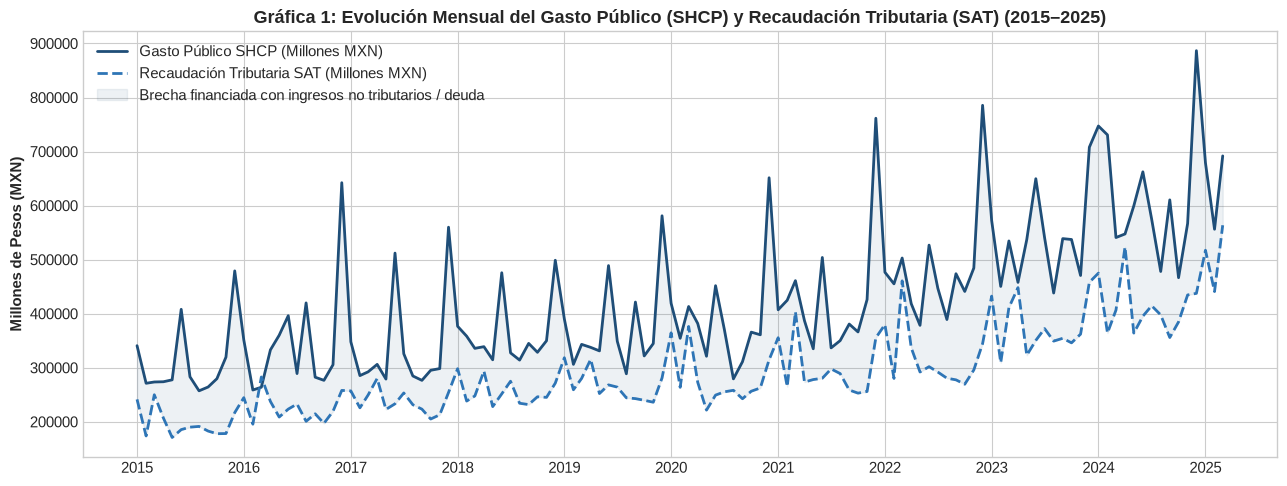

In [15]:
etapa(spark, '7_graficas')
pdf = df_analitico.toPandas()
pdf['fecha'] = pd.to_datetime(pdf['fecha'])

# Gráfica 1: Evolución Histórica de Gasto Público (SHCP) vs Recaudación Tributaria (SAT)
fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(pdf['fecha'], pdf['shcp_xbc'], color='#1f4e78', linewidth=2, label='Gasto Público SHCP (Millones MXN)')
ax1.plot(pdf['fecha'], pdf['sat_total_tributarios'], color='#2e75b6', linestyle='--', linewidth=2, label='Recaudación Tributaria SAT (Millones MXN)')
ax1.fill_between(pdf['fecha'], pdf['sat_total_tributarios'], pdf['shcp_xbc'], color='#1f4e78', alpha=0.08, label='Brecha financiada con ingresos no tributarios / deuda')
ax1.set_ylabel('Millones de Pesos (MXN)', fontweight='bold')
ax1.set_title('Gráfica 1: Evolución Mensual del Gasto Público (SHCP) y Recaudación Tributaria (SAT) (2015–2025)', fontsize=13, fontweight='bold')
ax1.legend(loc='upper left')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

**Lectura de la Gráfica 1:** Tanto el gasto del gobierno (línea azul continua) como el cobro de impuestos (línea punteada) subieron de forma constante entre 2015 y 2025. Se notan picos cada diciembre (cuando el gobierno cierra su presupuesto anual) y cada marzo/abril (cuando empresas y personas presentan su declaración anual ante el SAT). El área sombreada muestra la diferencia que el gobierno cubre con ingresos petroleros, derechos o deuda.

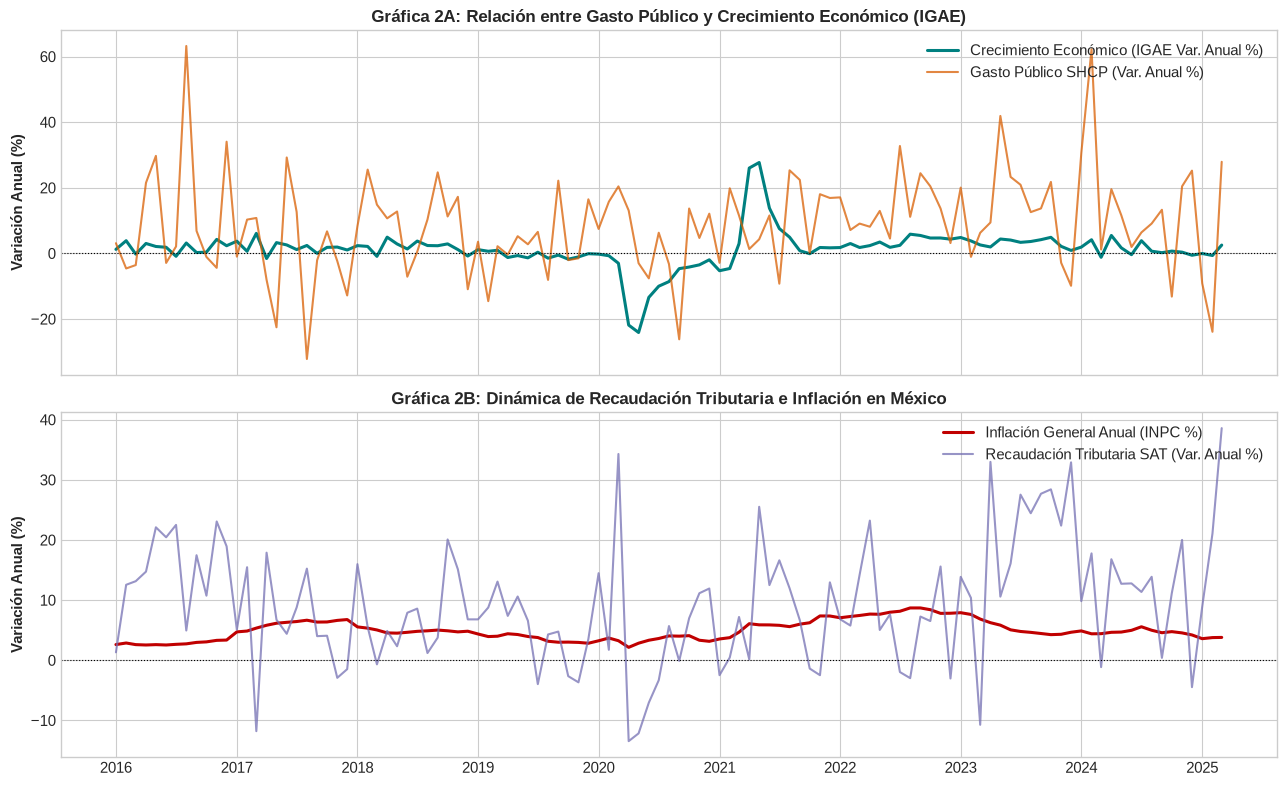

In [16]:
# Gráfica 2: Dinámica de Tasas Anuales: Gasto, Impuestos, Crecimiento (IGAE) e Inflación
pdf_clean = pdf.dropna(subset=['inflacion_anual_pct', 'gasto_var_anual_pct', 'sat_var_anual_pct'])

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Panel superior: Impulso fiscal vs Crecimiento económico
axes[0].plot(pdf_clean['fecha'], pdf_clean['igae_var_anual_pct'], color='#008080', linewidth=2.2, label='Crecimiento Económico (IGAE Var. Anual %)')
axes[0].plot(pdf_clean['fecha'], pdf_clean['gasto_var_anual_pct'], color='#d95f02', alpha=0.75, linewidth=1.5, label='Gasto Público SHCP (Var. Anual %)')
axes[0].axhline(0, color='black', linewidth=0.8, linestyle=':')
axes[0].set_ylabel('Variación Anual (%)', fontweight='bold')
axes[0].set_title('Gráfica 2A: Relación entre Gasto Público y Crecimiento Económico (IGAE)', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right')

# Panel inferior: Recaudación vs Inflación
axes[1].plot(pdf_clean['fecha'], pdf_clean['inflacion_anual_pct'], color='#c00000', linewidth=2.2, label='Inflación General Anual (INPC %)')
axes[1].plot(pdf_clean['fecha'], pdf_clean['sat_var_anual_pct'], color='#7570b3', alpha=0.75, linewidth=1.5, label='Recaudación Tributaria SAT (Var. Anual %)')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle=':')
axes[1].set_ylabel('Variación Anual (%)', fontweight='bold')
axes[1].set_title('Gráfica 2B: Dinámica de Recaudación Tributaria e Inflación en México', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

**Lectura de la Gráfica 2:**
- **Gráfica 2A (Arriba):** se nota claramente la caída económica de 2020 por la pandemia (`-24.11%`) y el rebote en 2021 (`+27.71%`). Visualmente el gasto no anticipa los movimientos del IGAE, en línea con las pruebas del Objetivo 1 (sin relación significativa en ningún rezago).
- **Gráfica 2B (Abajo):** el fuerte aumento de precios de 2021–2022 (hasta `8.70%`) coincidió con la reapertura mundial y problemas globales de transporte y suministro. La recaudación se mueve en sentido opuesto a la inflación sobre todo en la pospandemia (`r ≈ -0.43`, Sección 6).

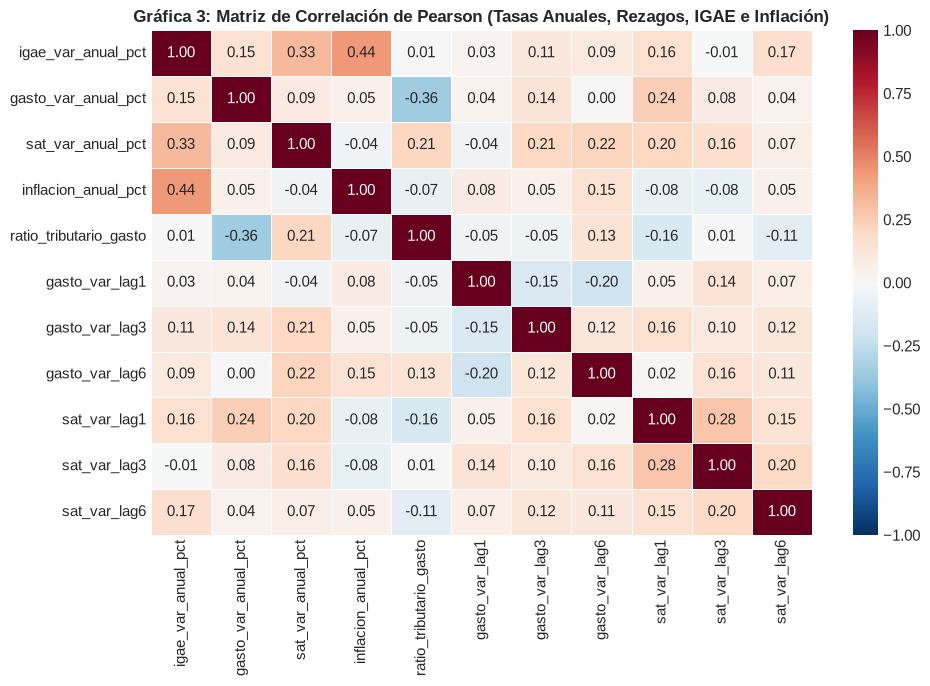

In [17]:
# Gráfica 3: Mapa de Calor de Correlaciones (Tasas y Rezagos)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    pdf_corr_tasas,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Gráfica 3: Matriz de Correlación de Pearson (Tasas Anuales, Rezagos, IGAE e Inflación)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura de la Gráfica 3:** este mapa de colores resume las relaciones de un vistazo. En rojo destaca que cuando la economía crece rápido (`igae_var_anual_pct`), también tienden a subir los precios (`0.44`) y aumenta la recaudación (`0.33`): son las dos relaciones más fuertes y las únicas significativas en toda la muestra. Las celdas casi blancas entre gasto, ratio e inflación (de `-0.09` a `0.15`) indican relaciones demasiado débiles para distinguirlas del azar (Paso 4C).

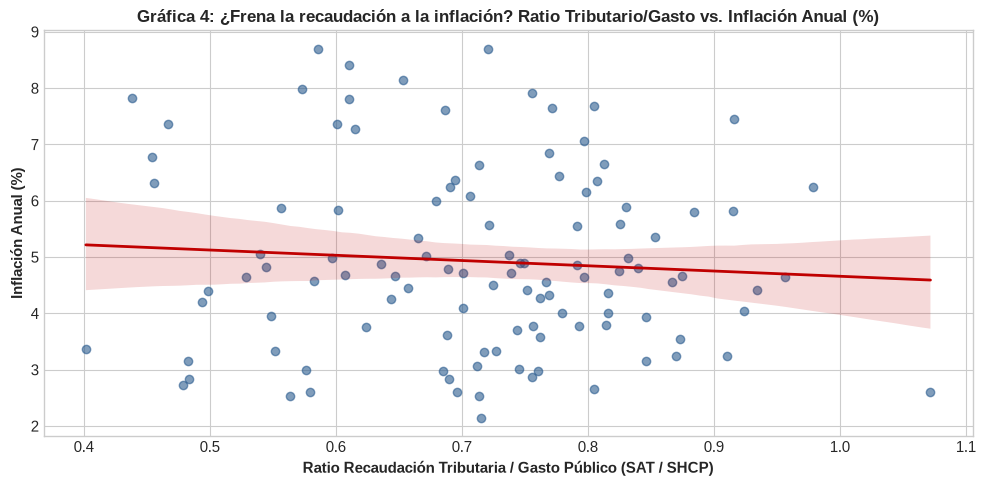

In [18]:
# Gráfica 4: Relación entre el Ratio Tributario/Gasto y la Inflación
fig, ax = plt.subplots(figsize=(10, 5))
sns.regplot(
    data=pdf_clean,
    x='ratio_tributario_gasto',
    y='inflacion_anual_pct',
    scatter_kws={'alpha': 0.6, 'color': '#2b5c8f'},
    line_kws={'color': '#c00000', 'linewidth': 2},
    ax=ax
)
ax.set_title('Gráfica 4: ¿Frena la recaudación a la inflación? Ratio Tributario/Gasto vs. Inflación Anual (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Ratio Recaudación Tributaria / Gasto Público (SAT / SHCP)', fontweight='bold')
ax.set_ylabel('Inflación Anual (%)', fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura de la Gráfica 4:** la línea roja baja ligeramente: en los meses en que una mayor parte del gasto se financia con impuestos, la inflación es algo menor. Pero la banda de confianza es amplia y la pendiente **no es significativa** (`r ≈ -0.07`; en la regresión con errores robustos, p > 0.5). Visualmente, la dispersión de puntos domina a la tendencia: la cobertura fiscal por sí sola **no** explica la inflación.

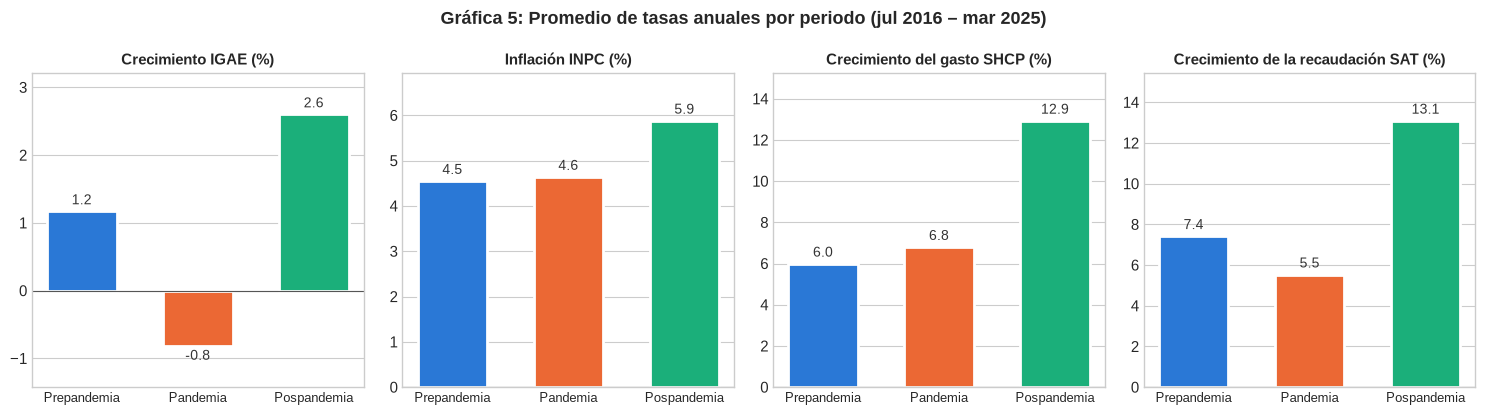

In [19]:
# Gráfica 5: Promedios por periodo (small multiples, un eje por indicador)
colores_periodo = ['#2a78d6', '#eb6834', '#1baf7a']  # azul, naranja, aqua: orden categorical fijo
indicadores = [
    ('igae_prom_pct', 'Crecimiento IGAE (%)'),
    ('inflacion_prom_pct', 'Inflación INPC (%)'),
    ('gasto_var_prom_pct', 'Crecimiento del gasto SHCP (%)'),
    ('sat_var_prom_pct', 'Crecimiento de la recaudación SAT (%)'),
]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=False)
etiquetas = [p.split('. ')[1] for p in pdf_periodos.periodo]
for ax, (col, titulo) in zip(axes, indicadores):
    barras = ax.bar(etiquetas, pdf_periodos[col], color=colores_periodo, width=0.6, edgecolor='white', linewidth=2)
    ax.bar_label(barras, fmt='%.1f', padding=3, fontsize=10, color='#333333')
    ax.axhline(0, color='#555555', linewidth=0.8)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='x', visible=False)
    ax.margins(y=0.18)
fig.suptitle('Gráfica 5: Promedio de tasas anuales por periodo (jul 2016 – mar 2025)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura de la Gráfica 5:** la pandemia es el único periodo con crecimiento promedio negativo (`-0.8 %`), y la pospandemia combina la mayor inflación (`5.9 %`) con el mayor crecimiento del gasto y de la recaudación (≈ `13 %` anual cada uno). Gasto y recaudación crecieron casi al mismo ritmo en cada periodo, por eso la cobertura fiscal (ratio) apenas cambió.

## 8. Cómo trabajó Spark durante el análisis

Cada sección etiquetó sus jobs con `etapa()`. La tabla resume, con datos de la Spark UI, cuánto trabajo hizo Spark en cada parte.

In [20]:
trabajo_spark = pd.DataFrame([metricas(spark, e) for e in
    ['2_carga', '3_indicadores', '4_objetivo1', '5_objetivo2', '6_periodos', '7_graficas']]).set_index('etapa')
trabajo_spark.loc['total'] = trabajo_spark.sum()
trabajo_spark

,jobs,stages,tareas,lectura_MB,escritura_MB,shuffle_KB,tiempo_tareas_s
etapa,,,,,,,
2_carga,6.0,6.0,36.0,0.64,0.0,21.1,18.32
3_indicadores,3.0,3.0,13.0,0.33,0.0,37.6,1.32
4_objetivo1,60.0,60.0,270.0,6.69,0.0,73.3,7.23
5_objetivo2,6.0,6.0,6.0,0.35,0.0,0.0,0.21
6_periodos,1.0,1.0,1.0,0.06,0.0,0.0,0.13
7_graficas,1.0,1.0,1.0,0.06,0.0,0.0,0.02
total,77.0,77.0,327.0,8.13,0.0,132.0,27.23


> **Lectura:**
> - En esta fase los datos ya son pequeños (123 filas, ~0.2 MB en Gold), así que **el costo de Spark lo marca el número de consultas, no el volumen**: cada `count`, `agg` o `corr` es un job con su planificación y sus tareas.
> - **El Objetivo 1 concentra la mayoría de los jobs** porque hace muchas consultas pequeñas: una tabla de significancia por horizonte y por variable dependiente, y el ciclo de robustez gasto total contra programable (un `agg` por rezago). La tabla de significancia agrupa todas las correlaciones de un horizonte en **un solo `agg`** para no lanzar un job por variable.
> - **La regresión (Objetivo 2) cuesta unos pocos jobs:** con `solver='normal'`, `LinearRegression` resuelve mínimos cuadrados en una pasada sobre los datos (calcula XᵀX y Xᵀy) y obtiene de ahí los errores estándar y los valores p.
> - **Las pruebas de Granger, ADF y los errores robustos (HAC) no lanzan jobs de Spark:** se calculan con `statsmodels` sobre la tabla mensual ya resumida por Spark (`toPandas()` de 105–123 filas). Distribuir 123 filas no aporta nada.
> - **Shuffle total ~130 KB:** solo la ventana y las agregaciones por periodo mueven datos entre particiones.

## 9. Resumen Final de Hallazgos y Conclusiones

| Pregunta del Proyecto | ¿Qué encontramos en los datos (2015–2025)? | Conclusión en lenguaje sencillo |
| :--- | :--- | :--- |
| **Objetivo 1:** Conexión y tiempo de efecto en el crecimiento económico (**IGAE**) | • Recaudación vs. IGAE: **`r ≈ 0.33`**, significativa, en el mismo mes.<br>• Gasto vs. IGAE: **sin relación significativa** en 0, 1, 3, 6 ni 12 meses.<br>• Granger: el **IGAE anticipa a la recaudación** (1–6 meses), no al revés. | Los impuestos suben **porque** la economía crece, no al revés. No encontramos evidencia de que el gasto público impulse el crecimiento en el corto plazo; solo en la pospandemia ambos se movieron juntos (`r ≈ 0.45`). |
| **Objetivo 2:** Efecto conjunto sobre la inflación (**INPC**) | • Modelo: R² ≈ **0.24** (≈ **0.41** con periodos).<br>• Recaudación: efecto **negativo y significativo** (errores robustos).<br>• Ratio tributario/gasto: **no significativo**.<br>• Granger: el **gasto anticipa la inflación a 5–6 meses**. | Una recaudación creciente coincide con **menor inflación**, y el gasto genera presión sobre los precios **con medio año de retraso**. El balance gasto/recaudación por sí solo no explica la inflación. |
| **Periodos** | Las relaciones aparecen sobre todo en pandemia y pospandemia; en la prepandemia ninguna es significativa. | La relación fiscal–economía **cambia con el contexto**; un promedio de 10 años la suaviza. |

### Limitaciones
- **Asociación, no causalidad.** Correlaciones, regresión y Granger muestran qué se mueve junto y qué va primero, no el mecanismo. Un efecto causal requeriría un diseño de identificación (por ejemplo, choques fiscales exógenos).
- **Pocas observaciones:** 105 meses en total y de 22 a 44 por periodo. Las relaciones débiles pueden no detectarse.
- **Variables omitidas:** el modelo de inflación no incluye tipo de cambio, precios internacionales ni la tasa de interés del Banco de México, porque el proyecto se limita a las cuatro fuentes oficiales (SHCP, SAT, IGAE e INPC). Por eso el R² no debe leerse como "lo que explica el gobierno".
- **Series persistentes:** la inflación anual, el crecimiento del gasto y el ratio no son estacionarios en esta ventana (prueba ADF, Paso 4D). Las pruebas de Granger y la regresión que los usan deben leerse con cautela.
- **Gasto total frente a programable:** el indicador usa el gasto total del Gobierno Federal (XBC), que incluye costo financiero de la deuda y participaciones. Con el gasto programable (XBC10) las conclusiones se mantienen (Paso 4E).
- **Cifras preliminares:** los meses más recientes del SAT pueden revisarse.

---

### Cierre y liberación de memoria en Spark
Para mantener limpio el entorno de trabajo, liberamos los datos guardados en memoria (`unpersist()`) y cerramos ordenadamente la sesión de PySpark.

In [21]:
df_analitico.unpersist()
spark.stop()
print('Sesión de Spark finalizada correctamente.')

Sesión de Spark finalizada correctamente.
